# Per-class F1 vs. class support — correlation & figure

Quantifies how strongly per-class detectability tracks class frequency, and renders
the report figure.

**Inputs:** per-class `f1` and `support` from the RF Config-2 test `classification_report`.
**Outputs:** Pearson r on log-support, Spearman ρ, log-linear fit, and a labelled scatter
(`f1_vs_logsupport.pdf` / `.png`).

The plotting code is identical whether you feed it the live model output or the committed
fallback table — only the *Load* cell changes.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

OUT_DIR = Path("/Users/amrabdullah/AI_2026ss/mlpc/report/figures")        # change to wherever you keep report figures
OUT_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.linewidth": 0.8,
    "mathtext.fontset": "cm",
})

## 1 — Load per-class F1 and support

**Option A (preferred):** plug in the DataFrame your `eval.classification_report` returns
for the RF Config-2 *test* predictions. It must be indexed by class name with `f1` and
`support` columns (drop the `*_avg` rows — the helper below does this).

**Option B (standalone fallback):** the committed RF Config-2 test numbers, so this notebook
reproduces the report figure even without re-running the model.


In [2]:
# ---- Option A: use your live result (uncomment and point at your variable) -------------
# report_df = clf_report_rf_test          # DataFrame from eval.classification_report(...)

# ---- Option B: committed fallback (RF Config 2, test set, val-selected thresholds) ------
report_df = pd.DataFrame(
    [   # class,                      f1,     support  (test positives)
        ("bell_ringing",              0.5159,  483),
        ("coffee_machine",           0.5382, 1236),
        ("cutlery_dishes",           0.5748, 2045),
        ("door_open_close",          0.3534, 1077),
        ("footsteps",                0.5002, 4256),
        ("keyboard_typing",          0.6547, 3333),
        ("keychain",                 0.5511, 1474),
        ("light_switch",             0.1217,   88),
        ("microwave",                0.6710, 2579),
        ("phone_ringing",            0.5953, 2076),
        ("running_water",            0.7591, 4190),
        ("toilet_flushing",          0.5699, 1076),
        ("vacuum_cleaner",           0.6651, 1992),
        ("wardrobe_drawer_open_close",0.2662, 569),
        ("window_open_close",        0.2235,  393),
    ],
    columns=["class", "f1", "support"],
).set_index("class")

# Optional: for the strict *learnability* framing, swap `support` for TRAIN positive counts.
# train_support = {  # approx = train_positive_rate% * 100166 (Strategy A train split)
#     "bell_ringing":1092,"coffee_machine":3786,"cutlery_dishes":6040,"door_open_close":3576,
#     "footsteps":11429,"keyboard_typing":9125,"keychain":4568,"light_switch":270,
#     "microwave":6821,"phone_ringing":6270,"running_water":12841,"toilet_flushing":3165,
#     "vacuum_cleaner":6401,"wardrobe_drawer_open_close":1983,"window_open_close":1292}
# report_df["support"] = report_df.index.map(train_support)

# Strip aggregate rows if present, extract aligned arrays
AVG_ROWS = ["macro avg", "micro avg", "weighted avg", "samples avg"]
per_class = report_df.drop(index=[r for r in AVG_ROWS if r in report_df.index])

names = per_class.index.tolist()
f1    = per_class["f1"].to_numpy(dtype=float)
sup   = per_class["support"].to_numpy(dtype=float)
logsup = np.log(sup)
print(f"{len(names)} classes loaded; macro F1 = {f1.mean():.4f}")

15 classes loaded; macro F1 = 0.5040


## 2 — Correlations

`log` only changes the **Pearson** value (it linearises the diminishing-returns shape of
"more data → higher F1"). **Spearman** is rank-based, so it is identical with or without the
log — it's reported as a transform-free robustness check.


In [3]:
r_log,  p_log  = stats.pearsonr(logsup, f1)   # the headline number
r_raw,  p_raw  = stats.pearsonr(sup,    f1)   # for contrast (no log)
rho,    p_rho  = stats.spearmanr(sup,   f1)   # log-invariant

slope, intercept = np.polyfit(logsup, f1, 1)
resid = f1 - (intercept + slope * logsup)

# Pearson sensitivity to the lowest-support outlier
order = np.argsort(sup)
r_drop, _ = stats.pearsonr(logsup[order][1:], f1[order][1:])

print(f"Pearson r ( ln(support), F1 ) = {r_log:.3f}  (p = {p_log:.4g})   <- headline")
print(f"Pearson r ( raw support, F1 ) = {r_raw:.3f}  (p = {p_raw:.4g})")
print(f"Spearman rho ( support, F1 )  = {rho:.3f}  (p = {p_rho:.4g})")
print(f"r^2 (log) = {r_log**2:.3f}  ->  {100*r_log**2:.0f}% of per-class F1 variance")
print(f"fit:  F1 ~= {intercept:.3f} + {slope:.3f} * ln(support)")
print(f"drop lowest-support class -> Pearson r = {r_drop:.3f}  (trend is not one outlier)")

Pearson r ( ln(support), F1 ) = 0.851  (p = 5.681e-05)   <- headline
Pearson r ( raw support, F1 ) = 0.706  (p = 0.003275)
Spearman rho ( support, F1 )  = 0.729  (p = 0.002065)
r^2 (log) = 0.725  ->  72% of per-class F1 variance
fit:  F1 ~= -0.561 + 0.149 * ln(support)
drop lowest-support class -> Pearson r = 0.766  (trend is not one outlier)


## 3 — Figure

Points coloured by residual sign (red = under-performs its support, blue = over-performs);
grey stems show the residual to the fit line. Labels are hand-placed to avoid overlap; any
class not in the offset table falls back to a default offset, so this still works if you
change the class set.


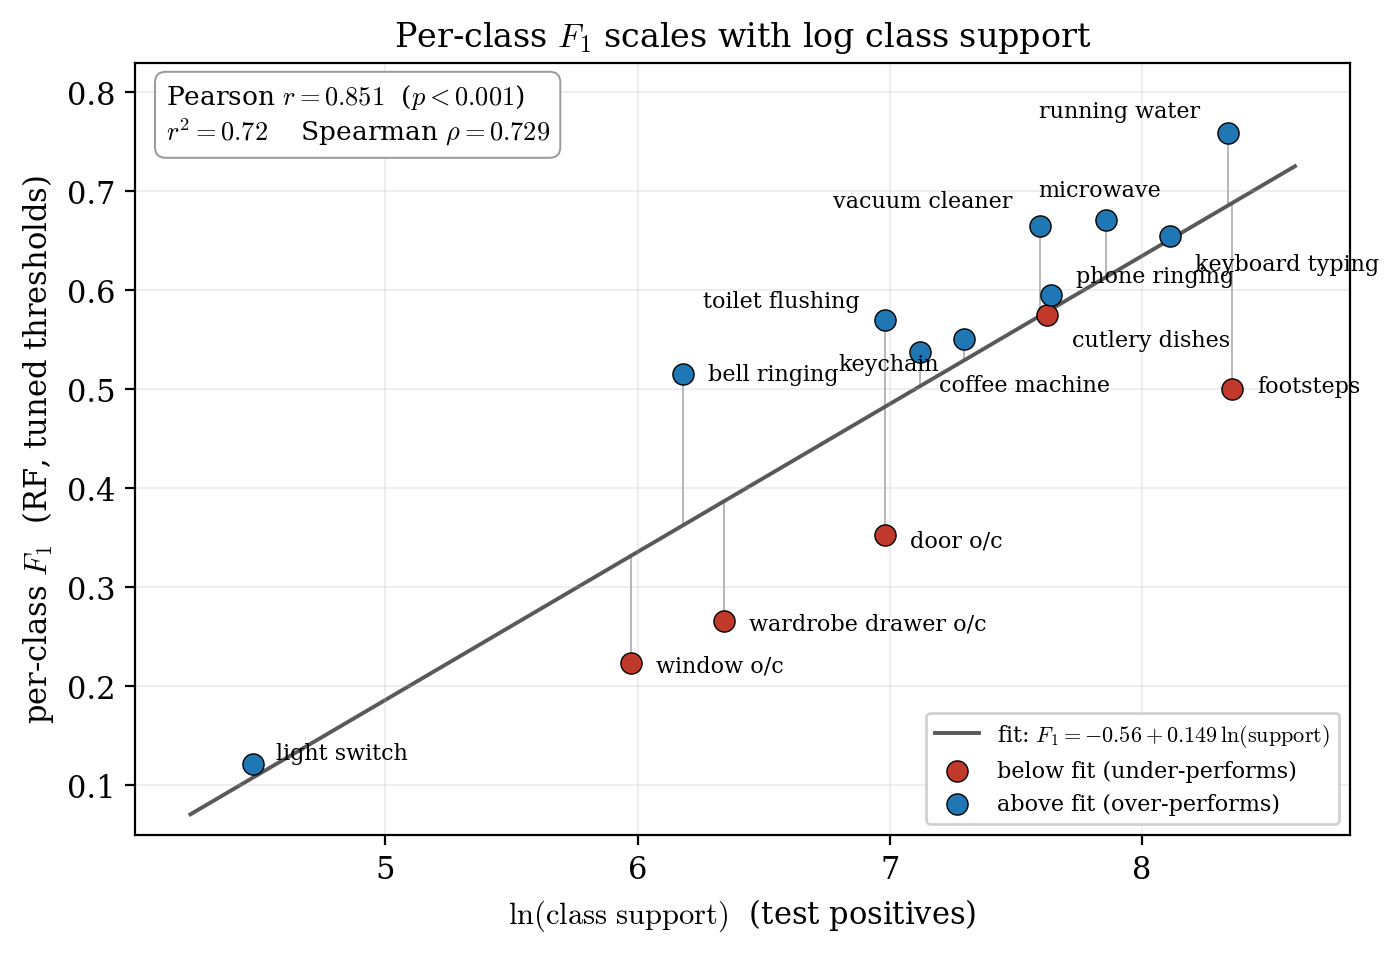

saved -> /Users/amrabdullah/AI_2026ss/mlpc/report/figures/f1_vs_logsupport.pdf


In [4]:
# hand-tuned label offsets in points: class -> (dx, dy, ha)
OFFSETS = {
    "light_switch":(8,4,"left"),  "window_open_close":(9,-1,"left"),
    "bell_ringing":(9,0,"left"),  "wardrobe_drawer_open_close":(9,-1,"left"),
    "toilet_flushing":(-9,7,"right"), "door_open_close":(9,-2,"left"),
    "coffee_machine":(7,-12,"left"),  "keychain":(-9,-9,"right"),
    "vacuum_cleaner":(-10,9,"right"), "cutlery_dishes":(9,-9,"left"),
    "phone_ringing":(9,7,"left"),     "microwave":(-2,11,"center"),
    "keyboard_typing":(9,-10,"left"), "running_water":(-10,8,"right"),
    "footsteps":(9,1,"left"),
}
DISPLAY = {"window_open_close":"window o/c", "door_open_close":"door o/c",
           "wardrobe_drawer_open_close":"wardrobe drawer o/c"}

fig, ax = plt.subplots(figsize=(7.2, 4.9), dpi=200)

xx = np.linspace(logsup.min()-0.25, logsup.max()+0.25, 100)
ax.plot(xx, intercept + slope*xx, color="0.35", lw=1.4, zorder=1,
        label=fr"fit: $F_1={intercept:.2f}+{slope:.3f}\,\ln(\mathrm{{support}})$")

for xi, yi, ri in zip(logsup, f1, resid):
    ax.plot([xi, xi], [yi, yi-ri], color="0.72", lw=0.7, zorder=0)

under = resid < 0
ax.scatter(logsup[under],  f1[under],  s=58, c="#c0392b", edgecolor="k", lw=0.5,
           zorder=3, label="below fit (under-performs)")
ax.scatter(logsup[~under], f1[~under], s=58, c="#1f78b4", edgecolor="k", lw=0.5,
           zorder=3, label="above fit (over-performs)")

for xi, yi, nm in zip(logsup, f1, names):
    dx, dy, ha = OFFSETS.get(nm, (9, 0, "left"))
    ax.annotate(DISPLAY.get(nm, nm.replace("_", " ")), (xi, yi),
                textcoords="offset points", xytext=(dx, dy),
                ha=ha, va="center", fontsize=8)

ax.set_xlabel(r"$\ln(\mathrm{class\ support})$  (test positives)")
ax.set_ylabel(r"per-class $F_1$  (RF, tuned thresholds)")
ax.set_title(r"Per-class $F_1$ scales with log class support", fontsize=12)
ax.text(0.025, 0.975,
        fr"Pearson $r={r_log:.3f}$  ($p<0.001$)" "\n"
        fr"$r^2={r_log**2:.2f}$    Spearman $\rho={rho:.3f}$",
        transform=ax.transAxes, va="top", ha="left", fontsize=9.5,
        bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="0.6", lw=0.7))
ax.legend(loc="lower right", fontsize=8, framealpha=0.92)
ax.grid(True, alpha=0.25, lw=0.6)
ax.set_ylim(0.05, 0.83)
fig.tight_layout()

fig.savefig(OUT_DIR / "f1_vs_logsupport.pdf", bbox_inches="tight")
fig.savefig(OUT_DIR / "f1_vs_logsupport.png", bbox_inches="tight", dpi=200)
plt.show()
print("saved ->", OUT_DIR / "f1_vs_logsupport.pdf")

## Notes

- **Which support?** This uses *test* positives (the `support` column of the report). For the
  causal "more training data → higher F1" claim, switch to *train* counts (commented block in
  the Load cell); the split's class priors are near-identical (KL = 0.0054) so `r` barely moves.
- **Which F1?** Per-class test F1 at the **validation-selected** thresholds for a *single* model
  (RF Config 2). Don't take per-class max over a test threshold sweep (optimistic) or per-class
  best across models (incoherent x-axis).
- **\\includegraphics{figures/f1_vs_logsupport.pdf}** for the report.
